# [14.3] Action-Conditioned World Models and Latent Planning (exercises)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part3_action_conditioned_planning/14.3_Action-Conditioned_World_Models_and_Latent_Planning_exercises.ipynb)
> |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part3_action_conditioned_planning/14.3_Action-Conditioned_World_Models_and_Latent_Planning_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

A cart starts at position 0, at rest. Its target is position 3, also at rest. An image of the target happens to have a blue background, while the current image has a red background. **Should the planner spend its effort moving the cart or changing the background?**

By the end of this notebook, you will have shown that an action-conditioned predictor can plan a controlled cart trajectory, whereas an action-shuffled predictor cannot, and that a goal metric should ignore an uncontrollable background coordinate. The evidence is a trajectory and error figure computed by your own dynamics, search and intervention functions.

We use a deliberately transparent organism: two physical coordinates and one nuisance coordinate. A least-squares predictor replaces the large video encoder and predictor. This lets us audit every imagined transition and actually optimize an action sequence on CPU. It is a planning lesson, not a one-step probe labelled planning. It is also **not a V-JEPA 2-AC reproduction**: learned video representations, robot actions and real-world success remain separate qualification work.

Prerequisites: NumPy broadcasting, least squares, state-space models and the latent-target idea in 14.1–14.2. The exact simulator is a teaching oracle available to us; the planner sees only its fitted predictor.

## Content & Learning Objectives

### 1️⃣ A world you can act on

> ##### Learning Objectives
>
> - Implement physical transitions and fit an action-conditioned latent predictor; contrast action-shuffled dynamics.

### 2️⃣ Imagine, score, and search

> ##### Learning Objectives
>
> - Roll out candidate actions and implement a bounded cross-entropy-method planner, checking a discrete exhaustive oracle.

### 3️⃣ Close the feedback loop

> ##### Learning Objectives
>
> - Compare open-loop plans with receding-horizon control under a changed actuator gain.

### 4️⃣ What is actually controllable?

> ##### Learning Objectives
>
> - Compute a controllability matrix and intervene separately on physical and nuisance coordinates.

## Setup code

This study edition uses tiny CPU fixtures: no network, pretrained checkpoint, GPU or additional installation.

In [ ]:
from pathlib import Path
import sys
import itertools
import numpy as np
import torch as t
import torch.nn.functional as F
import matplotlib.pyplot as plt
chapter = "chapter14_jepa_world_models"
section = "part3_action_conditioned_planning"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part3_action_conditioned_planning.tests as tests
MAIN = __name__ == "__main__"
device = t.device("cpu")
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ A world you can act on

> ##### Learning Objectives
>
> - Implement physical transitions and fit an action-conditioned latent predictor; contrast action-shuffled dynamics.

Our state is $s_t=(x_t,v_t,c_t)$: position, velocity and background colour, with action $a_t\in[-1,1]$. One unit of time gives
$$x_{t+1}=x_t+v_t+\tfrac12ga_t,\qquad v_{t+1}=v_t+ga_t,\qquad c_{t+1}=c_t.$$
The actuator gain $g$ is 1 while collecting the fixture. Colour persists but cannot be controlled. We intentionally expose $s$ as the latent $z$; learning an invariant visual encoder is outside this example.

Keep the batch axes: `state` has shape `(..., 3)` and `action` has shape `(...)`. We fit $z_{t+1}=[z_t,a_t,1]W$ with `W` shape `(5, 3)`. The intercept makes translation possible. Enumerating states and signed actions breaks the shortcut “action is always correlated with velocity.” A shuffled-action control has the same states, targets and parameter count, but destroys the causal action/transition alignment.

### Exercise - implement `world_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the simulator equation above without mutating the input. Return the same leading batch shape followed by three coordinates. `gain` belongs to the real environment, not to the learned model. We will later change it without refitting.

In [ ]:
def world_step(state, action, gain=1.0):
    raise NotImplementedError()


tests.test_world_step(world_step)

<details><summary>Hint</summary>

Use `np.stack` on the last axis. Do not clip position or velocity: only the planner bounds actions.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_world_step passed!`. For state `(0, 2, 8)` and action `1`, the next state is `(2.5, 3, 8)`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def world_step(state, action, gain=1.0):
    state = np.asarray(state, dtype=float)
    action = np.asarray(action, dtype=float)
    x, v, c = np.moveaxis(state, -1, 0)
    return np.stack([x + v + 0.5 * gain * action, v + gain * action, c + np.zeros_like(action)], axis=-1)
```
</details>

### Exercise - implement `transition_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Construct the regression design matrix. Inputs may be a single state or a batch. The final two columns must be action and a constant one, in that order; do not flatten the state/action correspondence.

In [ ]:
def transition_features(states, actions):
    raise NotImplementedError()


tests.test_transition_features(transition_features)

<details><summary>Hint</summary>

Concatenate on the feature axis; `actions[..., None]` adds the feature dimension.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_transition_features passed!`. The feature dimension is five, including the intercept.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def transition_features(states, actions):
    states = np.asarray(states, dtype=float)
    actions = np.asarray(actions, dtype=float)
    return np.concatenate([states, actions[..., None], np.ones_like(actions[..., None])], axis=-1)
```
</details>

### Exercise - implement `fit_dynamics`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit `W` by ordinary least squares. Return coefficients only. Use the library linear solve, not a matrix inverse: the fixture is small, and a rank-deficient design should still have a defined least-norm solution. This is supervised transition fitting, not self-supervised JEPA pretraining.

In [ ]:
def fit_dynamics(features, next_states):
    raise NotImplementedError()


tests.test_fit_dynamics(fit_dynamics)

<details><summary>Hint</summary>

`lstsq` returns a tuple; the first item is the coefficient matrix.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_fit_dynamics passed!`. The analytic two-feature fixture recovers coefficients `[[2,-1],[3,4]]`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def fit_dynamics(features, next_states):
    return np.linalg.lstsq(features, next_states, rcond=None)[0]
```
</details>

### Exercise - implement `predict_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Apply the fitted model using the same feature order as fitting. The model must support batched imagined states: later the planner will simulate many candidate futures at once. An action-free control is obtained by zeroing the action row of a fitted matrix, not by changing the simulator.

In [ ]:
def predict_step(states, actions, weights):
    raise NotImplementedError()


tests.test_predict_step(predict_step)

<details><summary>Hint</summary>

A matrix multiply contracts only the last feature dimension.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_predict_step passed!`. Signed actions affect both position and velocity; colour is unchanged.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def predict_step(states, actions, weights):
    return transition_features(states, actions) @ weights
```
</details>

In [ ]:
states = np.array(list(itertools.product([-2., 0., 2.], [-1., 0., 1.], [-1., 1.])))
train_states = np.repeat(states, 3, axis=0)
train_actions = np.tile([-1., 0., 1.], len(states))
targets = world_step(train_states, train_actions)
W = fit_dynamics(transition_features(train_states, train_actions), targets)
shuffled = np.random.default_rng(31).permutation(train_actions)
W_shuffled = fit_dynamics(transition_features(train_states, shuffled), targets)
print("Fitted action row:", W[3])
print("Shuffled action row:", W_shuffled[3])

<details><summary>Help - what should the action row mean?</summary>

The exact action row is `[0.5, 1, 0]`: a unit action shifts the next position by one half and next velocity by one, with no effect on colour. Check the shuffled row after execution; finite shuffling can leave accidental correlations, so it need not be exactly zero. Comparing against exact zero would be an unjustified expected-output claim.

</details>

## Summary of 1️⃣

We have fitted a transition map with explicit action alignment. Matching these coefficients establishes only this finite linear organism, not robot understanding.

# 2️⃣ Imagine, score, and search

> ##### Learning Objectives
>
> - Roll out candidate actions and implement a bounded cross-entropy-method planner, checking a discrete exhaustive oracle.

A planner needs **sequences**, not just one-step predictions. For a batch of `N` candidate sequences with horizon `H`, actions have shape `(N,H)` and the rollout has shape `(N,H+1,3)`, including the initial state. Score the terminal physical error plus an effort cost:
$$J(a_{0:H-1})=(x_H-x^*)^2+2(v_H-v^*)^2+0.02\sum_t a_t^2.$$
The goal colour is deliberately excluded. We first evaluate all $3^4=81$ sequences from `{-1,0,1}` at horizon four. This finite oracle validates search ordering and scoring, but it is not the solution to our continuous horizon-six problem.

For that problem implement the cross-entropy method (CEM): sample bounded sequences, retain the lowest-cost elite fraction, fit a factorized Gaussian to the elites and repeat. This is **our teaching optimizer**; do not infer that released V-JEPA 2-AC uses this exact optimizer or these hyperparameters. The minimum standard deviation prevents premature collapse. Keep the best sampled candidate across rounds, because refitting a distribution does not guarantee monotonic sample quality.

### Exercise - implement `imagine`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Unroll the learned dynamics for all candidate sequences. Include the initial state as index zero. Allocate a new state each step, so that appending it does not accidentally alias every timestep to the final state.

In [ ]:
def imagine(initial, actions, weights):
    raise NotImplementedError()


tests.test_imagine(imagine)

<details><summary>Hint</summary>

Loop over time, not over the candidate batch.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_imagine passed!`. The test trajectories are `[0,1,3]` and `[0,-1,-1]` in position.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def imagine(initial, actions, weights):
    actions = np.asarray(actions, dtype=float)
    state = np.broadcast_to(initial, (actions.shape[0], 3)).copy()
    trajectory = [state]
    for i in range(actions.shape[1]):
        state = predict_step(state, actions[:, i], weights)
        trajectory.append(state)
    return np.stack(trajectory, axis=1)
```
</details>

### Exercise - implement `goal_cost`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return one scalar cost per candidate. The optional colour weight deliberately permits a bad metric: later, changing it illustrates an irreducible goal mismatch. Do not include the initial state or average away the terminal error.

In [ ]:
def goal_cost(trajectories, actions, goal, nuisance_weight=0.0):
    raise NotImplementedError()


tests.test_goal_cost(goal_cost)

<details><summary>Hint</summary>

Square each coordinate before weighting. Sum effort over time only.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_goal_cost passed!`. Physical costs are `9.02` and `0`; the wrong-colour metric changes only the second to `12`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def goal_cost(trajectories, actions, goal, nuisance_weight=0.0):
    error = trajectories[:, -1] - np.asarray(goal)
    return error[:, 0]**2 + 2 * error[:, 1]**2 + nuisance_weight * error[:, 2]**2 + 0.02 * np.sum(actions**2, axis=1)
```
</details>

### Exercise - implement `select_elites`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Select the lowest-cost `count` candidates, preserving input order on ties. Stable ties matter in the exhaustive fixture and make the chosen public reference reproducible. Validate that there is at least one elite.

In [ ]:
def select_elites(actions, costs, count):
    raise NotImplementedError()


tests.test_select_elites(select_elites)

<details><summary>Hint</summary>

Use a stable ascending sort; do not select the largest rewards because these values are costs.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_select_elites passed!`. Candidates 1 and 2 are selected in that order.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def select_elites(actions, costs, count):
    if not 1 <= count <= len(actions):
        raise ValueError("elite count must be between one and population size")
    order = np.argsort(costs, kind="stable")[:count]
    return actions[order]
```
</details>

### Exercise - implement `cem_plan`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the complete bounded search, returning the best action sequence and best-so-far cost history. The distribution factorizes across time. Candidate zero is the current mean. This routine searches using only `weights`; simulator calls inside this function would leak the environment oracle.

In [ ]:
def cem_plan(initial, goal, weights, horizon=6, seed=7, population=256, rounds=7):
    raise NotImplementedError()


tests.test_cem_plan(cem_plan)

<details><summary>Hint</summary>

Separate best-so-far tracking from the elite distribution update.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_cem_plan passed!`. The independent integrator fixture reaches within squared error `0.08` of position 2, deterministically.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def cem_plan(initial, goal, weights, horizon=6, seed=7, population=256, rounds=7):
    rng = np.random.default_rng(seed)
    mean, std = np.zeros(horizon), np.ones(horizon)
    best, best_cost = mean.copy(), np.inf
    history = []
    for _ in range(rounds):
        candidates = np.clip(rng.normal(mean, std, size=(population, horizon)), -1., 1.)
        candidates[0] = mean
        costs = goal_cost(imagine(initial, candidates, weights), candidates, goal)
        j = int(np.argmin(costs))
        if costs[j] < best_cost:
            best, best_cost = candidates[j].copy(), float(costs[j])
        elite = select_elites(candidates, costs, max(2, population // 8))
        mean, std = elite.mean(axis=0), np.maximum(elite.std(axis=0), 0.08)
        history.append(best_cost)
    return best, np.asarray(history)
```
</details>


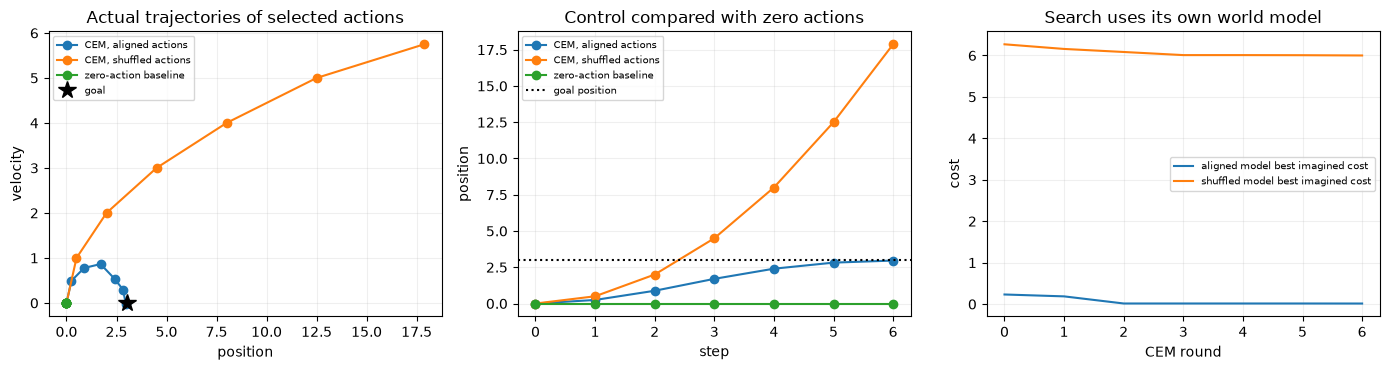

In [ ]:
initial, goal = np.array([0., 0., -1.]), np.array([3., 0., 1.])
discrete = np.array(list(itertools.product([-1., 0., 1.], repeat=4)))
costs4 = goal_cost(imagine(initial, discrete, W), discrete, goal)
oracle4 = discrete[np.argmin(costs4)]
plan, history = cem_plan(initial, goal, W)
bad_plan, bad_history = cem_plan(initial, goal, W_shuffled)
zero_plan = np.zeros(6)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for label, acts in [("CEM, aligned actions", plan), ("CEM, shuffled actions", bad_plan), ("zero-action baseline", zero_plan)]:
    real = [initial]
    for a in acts:
        real.append(world_step(real[-1], a))
    real = np.array(real)
    axes[0].plot(real[:, 0], real[:, 1], "o-", label=label)
    axes[1].plot(np.arange(7), real[:, 0], "o-", label=label)
    print(label, "terminal [x,v]", real[-1,:2].round(4), "true cost", round(float(goal_cost(real[None], acts[None], goal)[0]),4))
axes[0].plot([goal[0]], [goal[1]], "k*", ms=13, label="goal")
axes[0].set(xlabel="position", ylabel="velocity", title="Actual trajectories of selected actions")
axes[1].axhline(3., color="k", ls=":", label="goal position")
axes[1].set(xlabel="step", ylabel="position", title="Control compared with zero actions")
axes[2].plot(history, label="aligned model best imagined cost")
axes[2].plot(bad_history, label="shuffled model best imagined cost")
axes[2].set(xlabel="CEM round", ylabel="cost", title="Search uses its own world model")
for ax in axes: ax.legend(fontsize=7); ax.grid(alpha=.2)
fig.tight_layout(); plt.show()
print("81-sequence horizon-four oracle:", oracle4, "cost", round(float(costs4.min()),4))

<details><summary>Help - how should I interpret this?</summary>

The fixed CPU reference ends at `(2.9631, -0.0130)` with true cost `0.0135`; the shuffled-action model ends at `(17.8740, 5.7480)` with cost `287.4265`, while zero actions cost `9.0`. The discrete oracle selects `[1,0,0,-1]` with cost `0.04`. Read the phase portrait first: reaching position 3 at high velocity is not reaching the specified goal. The aligned model can both accelerate and brake. The shuffled model has seen the same transitions but has a corrupted relationship between action and consequence. Its low imagined cost, if achieved, is not a guarantee of low true cost. The zero-action baseline stays at the origin. The horizon-four oracle uses a different action domain and horizon; its cost is a search check, not a fairness claim against horizon-six CEM.

</details>

## Summary of 2️⃣

We constructed and scored complete futures, then used those scores to optimize actions. The trajectory is an actual closed physical outcome of the planned actions.

# 3️⃣ Close the feedback loop

> ##### Learning Objectives
>
> - Compare open-loop plans with receding-horizon control under a changed actuator gain.

Open-loop search commits to all actions. Model predictive control (MPC) instead observes the current state, plans a fresh horizon, executes only the first action and repeats. It can correct disturbances after observing their effect. It cannot correct a wrong objective, and model errors can still destabilize it.

Change the real actuator gain to `0.7` while retaining the model fitted at gain `1`. Run six decisions. For the MPC result we keep the planning horizon at six each time: it is a receding horizon, not the original terminal-time problem. This changes the optimization problem and spends more search work. Label that comparison honestly. We compare outcome distances, not claim equal-compute optimality.

### Exercise - implement `run_mpc`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Run the actual receding-horizon loop. Simulator calls belong here because these are executed actions. Feed the newly observed state into the next planner call. Return the visited states including the initial state and the executed action list.

In [ ]:
def run_mpc(initial, goal, weights, decisions=6, gain=1.0, seed=19):
    raise NotImplementedError()


tests.test_run_mpc(run_mpc)

<details><summary>Hint</summary>

Replan from `states[-1]`; do not reuse the initial state.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_run_mpc passed!`. The independent gain equations hold at every executed transition.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def run_mpc(initial, goal, weights, decisions=6, gain=1.0, seed=19):
    states, actions = [np.asarray(initial, dtype=float)], []
    for i in range(decisions):
        plan, _ = cem_plan(states[-1], goal, weights, seed=seed+i)
        actions.append(plan[0])
        states.append(world_step(states[-1], plan[0], gain=gain))
    return np.asarray(states), np.asarray(actions)
```
</details>

### Exercise - implement `physical_error`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Measure physical distance to the target at every timestep. This reporting metric weights position and velocity equally, unlike the planning cost. State that distinction rather than swapping metrics silently. Ignore colour in both.

In [ ]:
def physical_error(trajectory, goal):
    raise NotImplementedError()


tests.test_physical_error(physical_error)

<details><summary>Hint</summary>

Euclidean distance contracts the coordinate dimension, not time.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_physical_error passed!`. A `(3,4)` physical error has distance 5, irrespective of colour.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def physical_error(trajectory, goal):
    return np.sqrt(np.sum((trajectory[..., :2] - np.asarray(goal)[:2])**2, axis=-1))
```
</details>


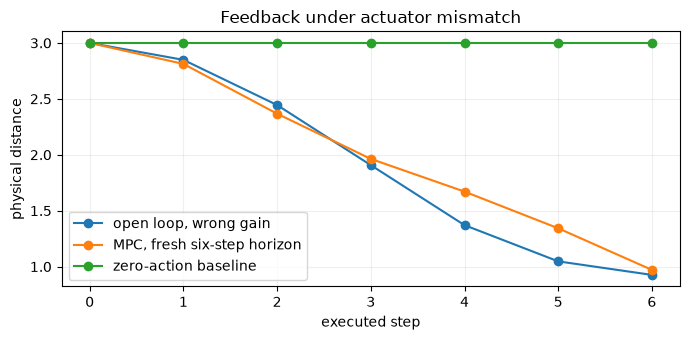

In [ ]:
open_states = [initial]
for a in plan: open_states.append(world_step(open_states[-1], a, gain=.7))
open_states = np.array(open_states)
mpc_states, mpc_actions = run_mpc(initial, goal, W, gain=.7)
zero_states = np.repeat(initial[None], 7, axis=0)
fig, ax = plt.subplots(figsize=(7,3.5))
for name, tr in [("open loop, wrong gain", open_states), ("MPC, fresh six-step horizon", mpc_states), ("zero-action baseline", zero_states)]:
    ax.plot(physical_error(tr, goal), "o-", label=name)
    print(name, "final physical distance", round(float(physical_error(tr, goal)[-1]),4))
ax.set(xlabel="executed step", ylabel="physical distance", title="Feedback under actuator mismatch")
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show()

## Summary of 3️⃣

The measured six-decision physical distances are `0.9259` for open loop, `0.9705` for MPC and `3.0` for zero actions. **MPC is slightly worse here.** Its fresh terminal horizon keeps postponing exact arrival, and each finite CEM call adds search error. Feedback is not a theorem of improvement under a changed objective and compute budget. Can you shrink the horizon as the deadline approaches and reverse this ordering? MPC changes the next action after seeing a model error. A shorter realized path to the target is evidence about this controller, not robustness of a released robot policy. The control uses zero actions and the baseline commits to the original open-loop sequence.

# 4️⃣ What is actually controllable?

> ##### Learning Objectives
>
> - Compute a controllability matrix and intervene separately on physical and nuisance coordinates.

For a linear system $z'=Az+Ba$, the columns of $\mathcal C=[B,AB,A^2B]$ span directions reachable by action sequences. Our regression stores row vectors, so `A = W[:3].T` and `B = W[3]`. The expected controllable rank is two. Colour is a third represented dimension, but not a reachable one.

Patch only colour between initial and goal latents, then only position/velocity. This intervention is straightforward because we chose a disentangled latent: it is **not evidence that an arbitrary visual encoder contains three separable causal variables**. The distinction between predictable, decodable and controllable is the point. A full learned encoder would require probes, counterfactual data and interventions aligned to real observations.

### Exercise - implement `controllability`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the reachability matrix of shape `(3,horizon)`. Do not include the intercept. This is a local linear concept: it says nothing about action bounds or nonlinear obstacles.

In [ ]:
def controllability(weights, horizon=3):
    raise NotImplementedError()


tests.test_controllability(controllability)

<details><summary>Hint</summary>

Transpose the state coefficient block because our fitted model multiplies state row vectors.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_controllability passed!`. The colour row is zero and the reachability rank is two.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def controllability(weights, horizon=3):
    A, B = weights[:3].T, weights[3]
    columns = []
    for _ in range(horizon):
        columns.append(B)
        B = A @ B
    return np.stack(columns, axis=1)
```
</details>

### Exercise - implement `patch_latent`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement a coordinate intervention without changing the source arrays. A colour patch should alter the nuisance part of the goal metric but leave physical error unchanged. A position/velocity patch changes the physical target relation.

In [ ]:
def patch_latent(recipient, donor, coordinates):
    raise NotImplementedError()


tests.test_patch_latent(patch_latent)

<details><summary>Hint</summary>

Make a copy before indexed assignment.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_patch_latent passed!`. Colour-only patch gives `(0,1,9)`; physical patch gives `(7,8,2)`.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def patch_latent(recipient, donor, coordinates):
    out = np.array(recipient, dtype=float, copy=True)
    out[..., coordinates] = np.asarray(donor)[..., coordinates]
    return out
```
</details>


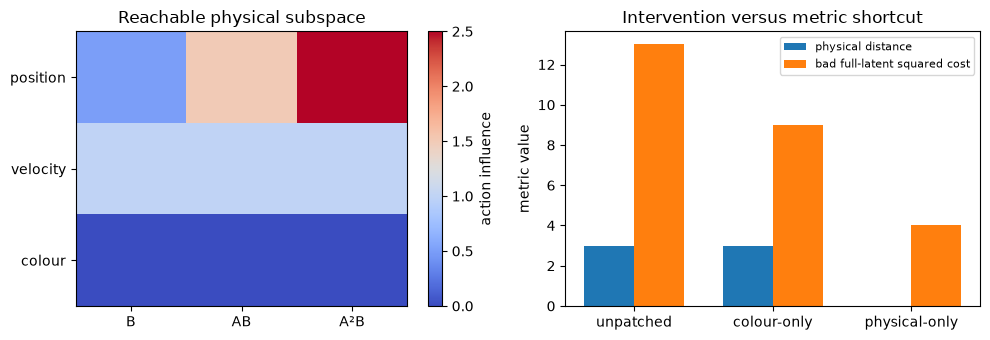

In [ ]:
C = controllability(W)
physical_patch = patch_latent(initial, goal, [0,1])
colour_patch = patch_latent(initial, goal, [2])
variants = [initial, colour_patch, physical_patch]
phys = [physical_error(v,goal) for v in variants]
full = [float(goal_cost(np.array(v)[None,None,:],np.zeros((1,0)),goal,nuisance_weight=1)[0]) for v in variants]
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
im=axes[0].imshow(C,aspect="auto",cmap="coolwarm");fig.colorbar(im,ax=axes[0],label="action influence")
axes[0].set(xticks=range(3),xticklabels=["B","AB","A²B"],yticks=range(3),yticklabels=["position","velocity","colour"],title="Reachable physical subspace")
xx=np.arange(3);axes[1].bar(xx-.18,phys,.36,label="physical distance");axes[1].bar(xx+.18,full,.36,label="bad full-latent squared cost")
axes[1].set(xticks=xx,xticklabels=["unpatched","colour-only","physical-only"],ylabel="metric value",title="Intervention versus metric shortcut");axes[1].legend(fontsize=8)
fig.tight_layout();plt.show()
print("controllability rank:",np.linalg.matrix_rank(C))
print("physical distances:",np.array(phys))
print("full-latent costs:",np.array(full))

## Interpreting the result

The cart starts three position units away with zero velocity. Patching colour leaves the physical distance at `3`; patching physical coordinates makes it `0`. The bad full-latent squared costs are `[13,9,4]`: its remaining colour error cannot be fixed by actions. A low feature distance can therefore mean a perceptual match or a controllable match, depending on which coordinates the metric rewards. The reachability map explains that distinction mechanistically.

## Try it yourself

Before running, predict the outcome when the initial velocity is `1` and the goal position is `-2`. Will the first action accelerate toward the goal or brake the existing motion? Change only these two values below and compare aligned, shuffled and zero-action trajectories. Then set real gain to `-0.7`: why might receding-horizon feedback with a wrong-sign model fail rather than repair the mismatch?

In [ ]:
play_initial, play_goal = np.array([0.,1.,-1.]), np.array([-2.,0.,1.])
play_plan, _ = cem_plan(play_initial, play_goal, W)
play_state, _ = run_mpc(play_initial, play_goal, W, gain=.7)
print("planned first action:",round(float(play_plan[0]),4))
print("feedback final physical distance:",round(float(physical_error(play_state,play_goal)[-1]),4))

## Limitations and bridge

This finite system establishes the mechanics of the visible predictor, planner and interventions only; the V-JEPA 2-AC visual representation, action/proprioception interface and robot generalization remain pending. We used exact state latents and a linear supervised predictor rather than self-supervised pretraining or robot video.

JEPA-VLA, ACT-JEPA and large robot models are reading/integration boundaries, not implemented model claims. Action-conditioned prediction answers “what would happen under these actions”; a VLA policy additionally maps language and observations to actions. A released robot system also needs embodiment calibration, temporal synchronization, collision constraints and human acceptance. None of these follows from a cart trajectory.

# ☆ Bonus

**Anomaly hunt:** increase the colour weight to 100. CEM can still optimize physical actions, but can it reduce the colour contribution below 400? Explain using the zero row of the controllability matrix. Then add actuator saturation inside the real environment only and inspect the earliest imagined/real mismatch.

**Changed-condition prediction:** hold the initial cart state and gain fixed; change the goal velocity from 0 to 1. Predict whether the best sequence will devote less effort to braking. This changes the task objective, unlike merely changing the CEM random seed.

## Further Reading

- [V-JEPA 2 paper](https://arxiv.org/abs/2506.09985): action-free pretraining and post-training an action-conditioned model for visual-goal planning are distinct stages. The paper supports that bridge, not this cart's success as robot evidence.
- [Official V-JEPA 2 / 2-AC code](https://github.com/facebookresearch/vjepa2): inspect the action/proprioception interface before proposing a native implementation.
- [ACT-JEPA](https://arxiv.org/abs/2501.14622): jointly predicts action sequences and latent observation sequences, combining imitation and self-supervised learning. Our cart planner has neither its demonstration objective nor its action-sequence policy.
- [VLA-JEPA](https://arxiv.org/abs/2602.10098): compare its current-view student and future-view target with action-head fine-tuning. This is a named reading comparison.
- [TD-MPC2 paper](https://arxiv.org/abs/2310.16828): decoder-free latent dynamics and local trajectory optimization provide a useful comparison; section 14.7 implements its objective components separately.